# Ανίχνευση και Ανάλυση Θαλάσσιων Καυσώνων στην Ανατολική Μεσόγειο με Δορυφορικά Δεδομένα SST

*Detection and Analysis of Marine Heatwaves in the Eastern Mediterranean using Satellite SST Data*

**Περιοχή μελέτης:** Πατραϊκός Κόλπος (σημείο-αναφορά) & Ιόνιο ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου (χωρική ανάλυση)
**Περίοδος:** 2014–2026
**Δεδομένα:** Copernicus Marine Service — Mediterranean SST L4 Reprocessed (0.05°, ημερήσια)
**Μεθοδολογία:** Hobday et al. (2016, 2018), υλοποιημένη μέσω της βιβλιοθήκης [`xmhw`](https://github.com/coecms/xmhw)

## Σκοπός

Ανίχνευση επεισοδίων θαλάσσιου καύσωνα (Marine Heatwaves) σε σημείο-αναφορά στον Πατραϊκό Κόλπο,
καθώς και χωρική ανάλυση έντασης/συχνότητας καυσώνων στο Ιόνιο Πέλαγος, ανοιχτά
Κυλλήνης-Κεφαλονιάς-Αράξου.


## 1. Λήψη Δεδομένων — Σημείο Αναφοράς (Πατραϊκός Κόλπος, 2014–2026)

Λήψη ημερήσιας χρονοσειράς SST για μικρή περιοχή γύρω από το σημείο μελέτης, μέσω του επίσημου
Python client του Copernicus Marine Service.


In [1]:
import copernicusmarine

copernicusmarine.subset(
    dataset_id="cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021",
    variables=["analysed_sst"],
    minimum_longitude=21.68,
    maximum_longitude=21.78,
    minimum_latitude=38.20,
    maximum_latitude=38.30,
    start_datetime="2014-01-01T00:00:00",
    end_datetime="2026-07-31T00:00:00",
    output_filename="sst_2014_2026_patra.nc",
    output_directory="./data"
)

C:\Users\User\PycharmProjects\PythonProject1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO - 2026-08-22T09:14:51Z - Selected dataset version: "202411"
INFO - 2026-08-22T09:14:51Z - Selected dataset part: "default"
WARNING - 2026-08-22T09:14:51Z - Some of your subset selection [2014-01-01 00:00:00+00:00, 2026-07-31 00:00:00+00:00] for the time dimension exceed the dataset coordinates [1982-01-01 00:00:00+00:00, 2026-07-23 00:00:00+00:00]
INFO - 2026-08-22T09:14:59Z - Total size of the download: 49.17 KB.


ResponseSubset(file_path=WindowsPath('data/sst_2014_2026_patra_(1).nc'), output_directory=WindowsPath('data'), filename='sst_2014_2026_patra_(1).nc', file_size=0.048015267175572515, data_transfer_size=18.30302290076336, variables=['analysed_sst'], coordinates_extent=[GeographicalExtent(minimum=21.71158218383789, maximum=21.761627197265625, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=38.20039367675781, maximum=38.250553131103516, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2014-01-01T00:00:00+00:00', maximum='2026-07-23T00:00:00+00:00', unit='iso8601', coordinate_id='time')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

## 2. Ανίχνευση Θαλάσσιου Καύσωνα — Σημείο Αναφοράς

Υπολογισμός climatology baseline, κατωφλίου (90ό εκατοστημόριο) και ανίχνευση επεισοδίων με τη
μέθοδο Hobday, πάνω στη χρονοσειρά του σημείου αναφοράς.


In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from xmhw.xmhw import threshold, detect

# Άνοιγμα δεδομένων & προετοιμασία χρονοσειράς
ds = xr.open_dataset("data/sst_2014_2026_patra.nc")

sst = ds["analysed_sst"].mean(dim=["latitude", "longitude"]) - 273.15
sst.name = "sst"

# Climatology (seas) + κατώφλι (thresh)
clim = threshold(sst)

# Ανίχνευση επεισοδίων καύσωνα
mhw = detect(sst, clim["thresh"], clim["seas"])

n_events = int(mhw["duration"].dropna(dim="events").size)
print(f"Αριθμός επεισοδίων θαλάσσιου καύσωνα που ανιχνεύθηκαν: {n_events}")

calendar not in keys
Αριθμός επεισοδίων θαλάσσιου καύσωνα που ανιχνεύθηκαν: 32


### Τα 5 πιο έντονα επεισόδια (κατά μέγιστη ένταση)

In [3]:
if n_events > 0:
    valid = mhw.dropna(dim="events", subset=["duration"])
    top5 = valid.sortby("intensity_max", ascending=False).isel(events=slice(0, 5))

    print("Τα 5 πιο έντονα επεισόδια:")
    for i in range(top5.sizes["events"]):
        start = top5["time_start"].values[i]
        end = top5["time_end"].values[i]
        duration = top5["duration"].values[i]
        intensity = top5["intensity_max"].values[i]
        category = top5["category"].values[i]
        print(f"  - Έναρξη: {np.datetime_as_string(start, unit='D')}, "
              f"Λήξη: {np.datetime_as_string(end, unit='D')}, "
              f"Διάρκεια: {duration:.0f} ημέρες, "
              f"Μέγιστη ένταση: {intensity:.2f} °C, "
              f"Κατηγορία: {category}")

Τα 5 πιο έντονα επεισόδια:
  - Έναρξη: 2024-03-29, Λήξη: 2024-04-18, Διάρκεια: 21 ημέρες, Μέγιστη ένταση: 3.12 °C, Κατηγορία: 2.0
  - Έναρξη: 2022-06-01, Λήξη: 2022-06-07, Διάρκεια: 7 ημέρες, Μέγιστη ένταση: 2.85 °C, Κατηγορία: 1.0
  - Έναρξη: 2024-08-05, Λήξη: 2024-09-19, Διάρκεια: 46 ημέρες, Μέγιστη ένταση: 2.76 °C, Κατηγορία: 2.0
  - Έναρξη: 2021-06-25, Λήξη: 2021-07-03, Διάρκεια: 9 ημέρες, Μέγιστη ένταση: 2.74 °C, Κατηγορία: 1.0
  - Έναρξη: 2023-10-20, Λήξη: 2023-11-01, Διάρκεια: 13 ημέρες, Μέγιστη ένταση: 2.65 °C, Κατηγορία: 1.0


### Οπτικοποίηση: SST, Climatology, Κατώφλι & Επεισόδια Καύσωνα

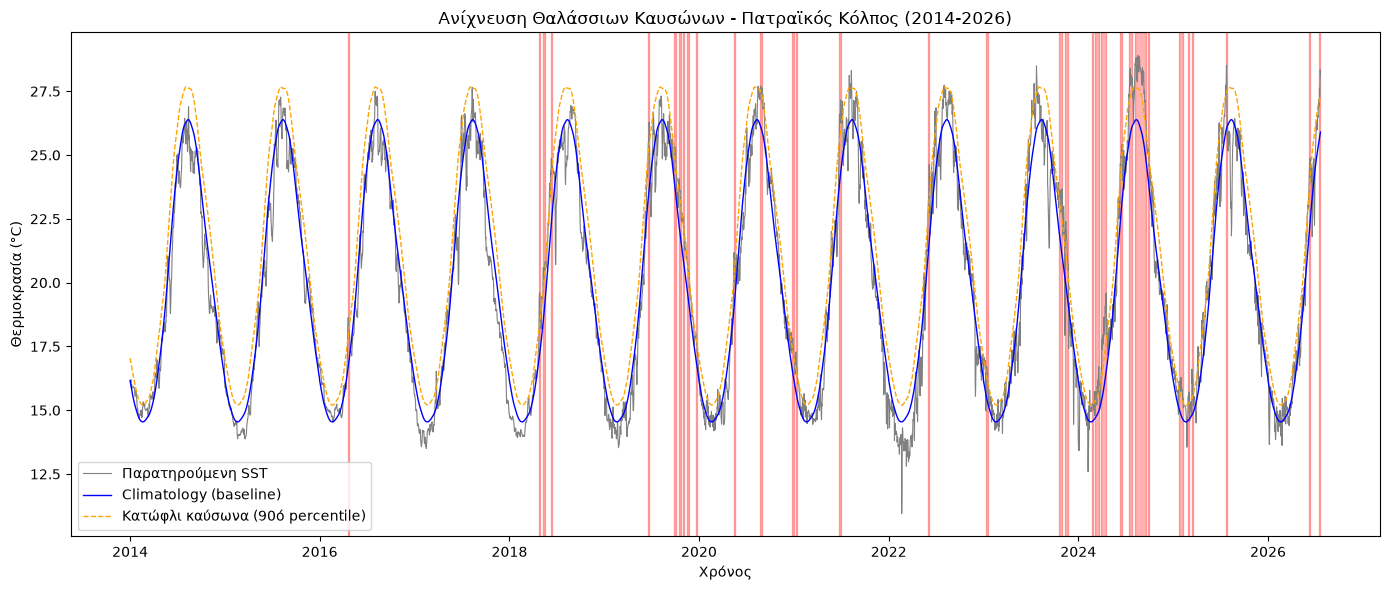

In [4]:
# "Άπλωμα" του climatology/thresh στη διάσταση χρόνου (από day-of-year σε πλήρη χρονοσειρά)
doy = sst["time"].dt.dayofyear
seas_ts = clim["seas"].sel(doy=doy)
thresh_ts = clim["thresh"].sel(doy=doy)

plt.figure(figsize=(14, 6))
sst.plot(color="gray", linewidth=0.8, label="Παρατηρούμενη SST")
seas_ts.plot(color="blue", linewidth=1, label="Climatology (baseline)")
thresh_ts.plot(color="orange", linewidth=1, linestyle="--", label="Κατώφλι καύσωνα (90ό percentile)")

if n_events > 0:
    valid = mhw.dropna(dim="events", subset=["duration"])
    for i in range(valid.sizes["events"]):
        start = valid["time_start"].values[i]
        end = valid["time_end"].values[i]
        plt.axvspan(start, end, color="red", alpha=0.3)

plt.title("Ανίχνευση Θαλάσσιων Καυσώνων - Πατραϊκός Κόλπος (2014-2026)")
plt.xlabel("Χρόνος")
plt.ylabel("Θερμοκρασία (°C)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Λήψη Δεδομένων — Ευρύτερη Περιοχή (Χωρική Ανάλυση)

Λήψη δεδομένων SST για μικρή περιοχή στο Ιόνιο Πέλαγος, ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου (δυτικά της εισόδου του Πατραϊκού Κόλπου), ώστε να αναλυθούν
χωρικά μοτίβα έντασης και συχνότητας καυσώνων.


In [5]:
import copernicusmarine

copernicusmarine.subset(
    dataset_id="cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021",
    variables=["analysed_sst"],
    minimum_longitude=20.77,
    maximum_longitude=21.45,
    minimum_latitude=37.90,
    maximum_latitude=38.30,
    start_datetime="2014-01-01T00:00:00",
    end_datetime="2026-07-31T00:00:00",
    output_filename="sst_region_small.nc",
    output_directory="./data"
)

INFO - 2026-08-22T09:15:38Z - Selected dataset version: "202411"
INFO - 2026-08-22T09:15:38Z - Selected dataset part: "default"
WARNING - 2026-08-22T09:15:38Z - Some of your subset selection [2014-01-01 00:00:00+00:00, 2026-07-31 00:00:00+00:00] for the time dimension exceed the dataset coordinates [1982-01-01 00:00:00+00:00, 2026-07-23 00:00:00+00:00]
INFO - 2026-08-22T09:15:52Z - Total size of the download: 829.03 KB.


ResponseSubset(file_path=WindowsPath('data/sst_region_small_(1).nc'), output_directory=WindowsPath('data'), filename='sst_region_small_(1).nc', file_size=0.8095973282442748, data_transfer_size=73.21209160305344, variables=['analysed_sst'], coordinates_extent=[GeographicalExtent(minimum=20.810752868652344, maximum=21.411304473876953, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=37.949607849121094, maximum=38.250553131103516, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2014-01-01T00:00:00+00:00', maximum='2026-07-23T00:00:00+00:00', unit='iso8601', coordinate_id='time')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

## 4. Χωρική Ανάλυση: Ανίχνευση Καύσωνα σε Κάθε Σημείο Πλέγματος

Εφαρμογή της ίδιας μεθοδολογίας ανίχνευσης σε κάθε σημείο του χωρικού πλέγματος στο Ιόνιο
(ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου) — 91 σημεία, grid 7×13 — ώστε να εντοπιστούν περιοχές με
υψηλότερη ένταση/συχνότητα καυσώνων.


In [6]:
ds_region = xr.open_dataset("data/sst_region_small.nc")
sst_region = ds_region["analysed_sst"] - 273.15
sst_region.name = "sst"
print(sst_region.shape)  # (χρόνος, latitude, longitude)

clim_region = threshold(sst_region)
mhw_region = detect(sst_region, clim_region["thresh"], clim_region["seas"])

(4586, 7, 13)
calendar not in keys


C:\Users\User\PycharmProjects\PythonProject1\.venv\Lib\site-packages\xmhw\xmhw.py:210: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  ds["thresh"] = xr.concat(thresh_results, dim='cell')
C:\Users\User\PycharmProjects\PythonProject1\.venv\Lib\site-packages\xmhw\xmhw.py:211: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitl

### Χάρτης: Μέγιστη Ένταση Καύσωνα ανά Σημείο

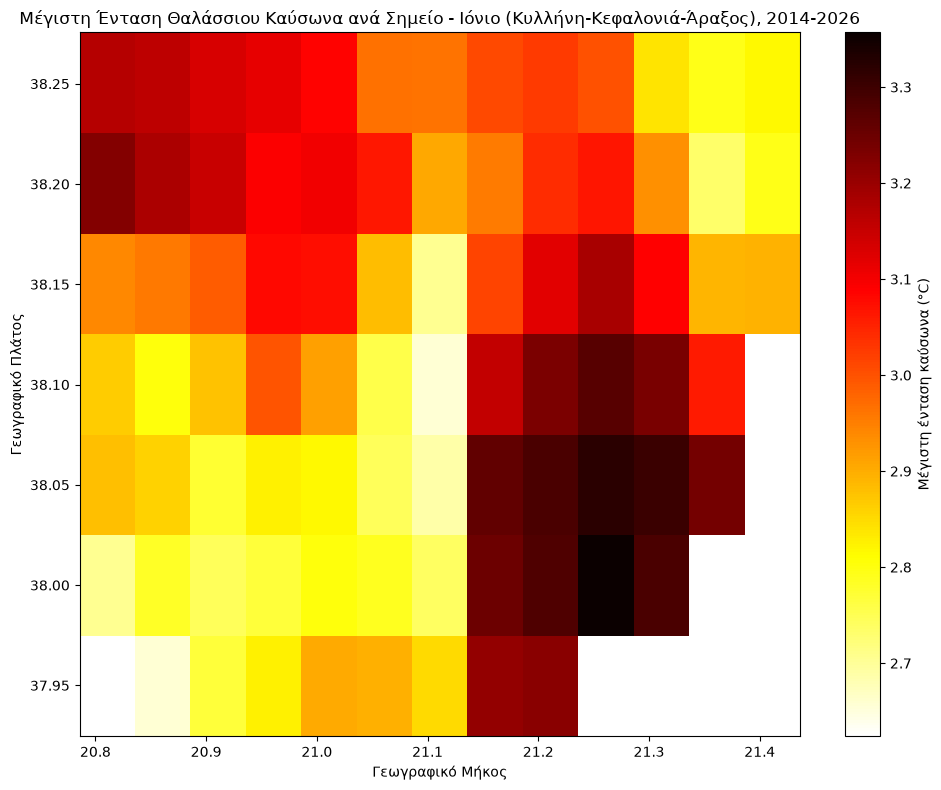

In [7]:
max_intensity_map = mhw_region["intensity_max"].max(dim="events", skipna=True)

plt.figure(figsize=(10, 8))
max_intensity_map.plot(cmap="hot_r", cbar_kwargs={"label": "Μέγιστη ένταση καύσωνα (°C)"})
plt.title("Μέγιστη Ένταση Θαλάσσιου Καύσωνα ανά Σημείο - Ιόνιο (Κυλλήνη-Κεφαλονιά-Άραξος), 2014-2026")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

### Χάρτης: Συνολικός Αριθμός Επεισοδίων ανά Σημείο

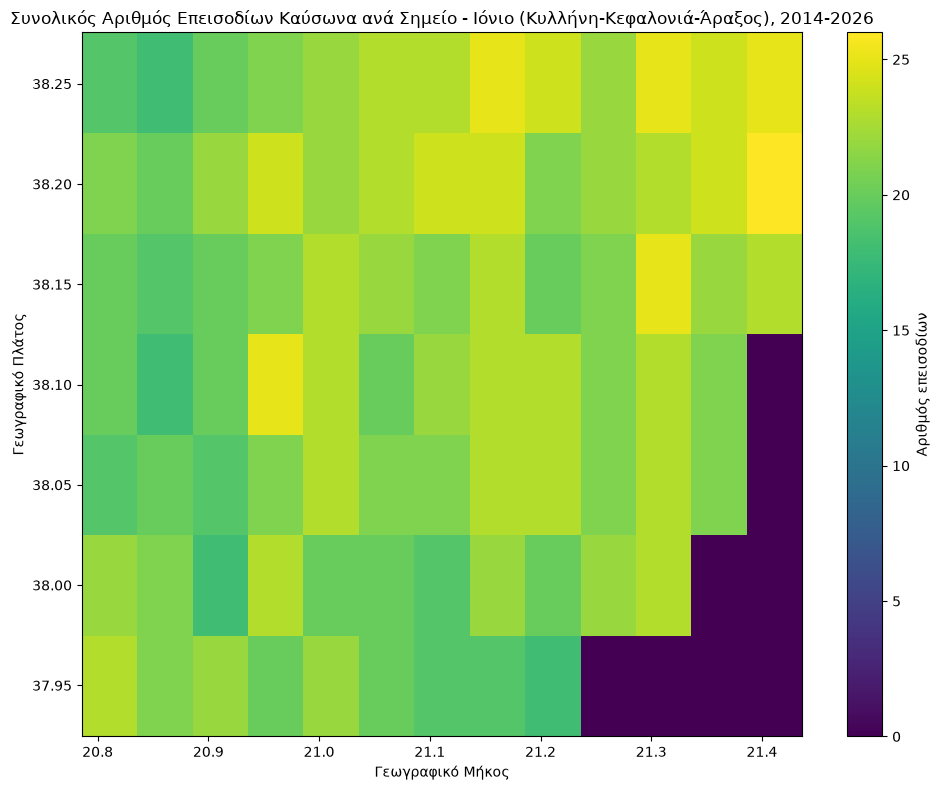

In [8]:
n_events_map = mhw_region["duration"].count(dim="events")

plt.figure(figsize=(10, 8))
n_events_map.plot(cmap="viridis", cbar_kwargs={"label": "Αριθμός επεισοδίων"})
plt.title("Συνολικός Αριθμός Επεισοδίων Καύσωνα ανά Σημείο - Ιόνιο (Κυλλήνη-Κεφαλονιά-Άραξος), 2014-2026")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

## 5. Έλεγχος Ποιότητας Δεδομένων

Οι περιοχές με μηδενικά επεισόδια στον παραπάνω χάρτη αντιστοιχούν σε σημεία πάνω σε **ξηρά**
(ακτογραμμή εντός του bounding box), όχι σε σφάλμα ανάλυσης. Επιβεβαιώνεται παρακάτω μέσω ελέγχου
ελλειπών τιμών (NaN), και επαληθεύτηκε οπτικά μέσω Google Earth.


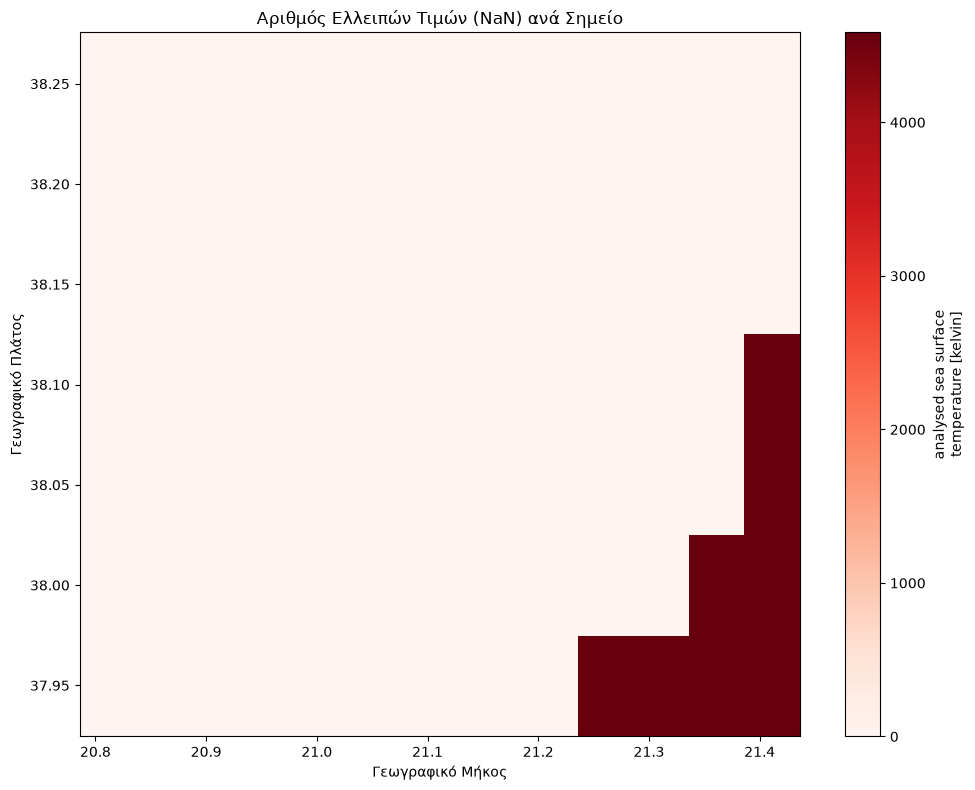

In [9]:
nan_count = sst_region.isnull().sum(dim="time")

plt.figure(figsize=(10, 8))
nan_count.plot(cmap="Reds")
plt.title("Αριθμός Ελλειπών Τιμών (NaN) ανά Σημείο")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

## 6. Συμπεράσματα

- Εντοπίστηκαν πολλαπλά επεισόδια θαλάσσιου καύσωνα στην περιοχή μελέτης κατά την περίοδο 2014–2026.
- Το **2024** ξεχώρισε ως έτος-ρεκόρ: το πιο έντονο επεισόδιο (21 ημέρες, Μάρτιος–Απρίλιος 2024,
  ένταση 3.12°C) και το μεγαλύτερης διάρκειας επεισόδιο (46 ημέρες, Αύγουστος–Σεπτέμβριος 2024) της
  περιόδου μελέτης καταγράφηκαν αυτό το έτος.
- Η χωρική ανάλυση στο Ιόνιο (Κυλλήνη-Κεφαλονιά-Άραξος) έδειξε διαφοροποίηση έντασης/συχνότητας
  καύσωνα εντός του πλέγματος, με πιθανή σύνδεση με τοπικά βαθυμετρικά και υδρογραφικά χαρακτηριστικά
  της περιοχής.
- Τα ευρήματα ευθυγραμμίζονται με τη διεθνή βιβλιογραφία που χαρακτηρίζει τη Μεσόγειο ως κλιματικό
  hotspot, με αυξανόμενη συχνότητα και ένταση θαλάσσιων καυσώνων τα τελευταία χρόνια.

### Περιορισμοί

- Το climatology baseline βασίζεται σε ~12 χρόνια δεδομένων· ο επίσημος ορισμός Hobday προτείνει
  τουλάχιστον 30ετία για πλήρως αντιπροσωπευτικό baseline.
- Το bounding box της χωρικής ανάλυσης περιλαμβάνει τμήματα ξηράς, τα οποία εμφανίζονται ως περιοχές
  χωρίς έγκυρα δεδομένα.

### Βιβλιογραφία

- Hobday, A.J. et al. (2016). *A hierarchical approach to defining marine heatwaves.* Progress in Oceanography.
- Hobday, A.J. et al. (2018). *Categorizing and naming marine heatwaves.* Oceanography, 31(2), 162-173.
- Pastor, F., Paredes-Fortuny, L. & Khodayar, S. (2024). *Mediterranean marine heatwaves intensify in
  the presence of concurrent atmospheric heatwaves.* Communications Earth & Environment.
